In [13]:
%matplotlib inline

import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os
import glob

In [17]:
# Load data
def load_data(data_path):
    if os.path.isfile(data_path):
        data = np.genfromtxt(data_path, names=True, delimiter=",")
        return data
    else:
        return None

def load_csv_files(directory):
    csv_files = glob.glob(os.path.join(directory, '*.csv'))

    data_dict = {}

    for csv_file in csv_files:
        data = load_data(csv_file)
        label = os.path.splitext(os.path.basename(csv_file))[0]
        data_dict[label] = data

    return data_dict

data_dict = load_csv_files("")


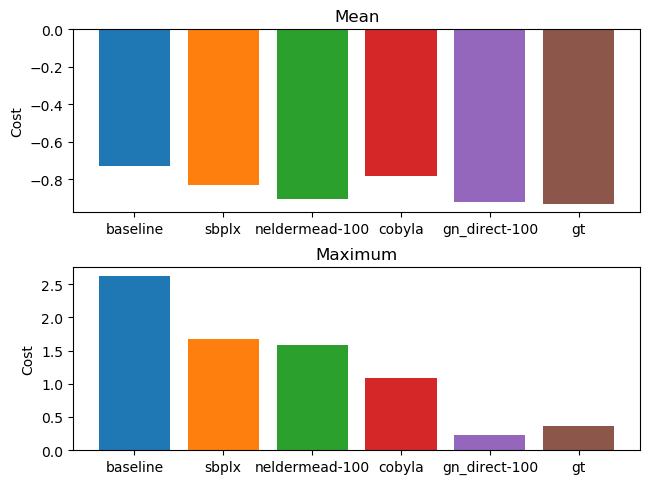

In [27]:
def compute_statistics(data):
    mean = np.mean(data)
    minimum = np.min(data)
    maximum = np.max(data)

    return mean, minimum, maximum

def plot_statistics(axs, data_dict):
    algorithms = []
    means = []
    maxs = []
    for label, data in data_dict.items():
        mean, _, maximum = compute_statistics(data["cost"])
        algorithms.append(label)
        means.append(mean)
        maxs.append(maximum)

    ax_mean, ax_max = axs
    colors = matplotlib.colors.TABLEAU_COLORS
    ax_mean.bar(algorithms, means, color=colors)
    ax_mean.set_title("Mean")
    ax_mean.set_ylabel("Cost")

    ax_max.bar(algorithms, maxs, color=colors)
    ax_max.set_title("Maximum")
    ax_max.set_ylabel("Cost")



fig, axs = plt.subplots(2,1)
fig.tight_layout()
fig.subplots_adjust(hspace=0.3)
plot_statistics(axs, data_dict)

